# For inference

- We used directories of mel spectrograms to generate sound classes predictions from SCQ-U-CNN. 
- Each class directory will result in one csv, according to testing and training/validation joined. 
- Each row of the csv corresponds to a single mel.

In [1]:
import tensorflow as tf
from tensorflow.keras.saving import register_keras_serializable

'''
%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=1
'''

from sklearn.metrics import roc_auc_score, roc_curve
import IPython.display as display
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import pathlib
import glob
import joblib

from uvne_packs.losses import FocalLossMultilabel

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
AUTOTUNE = tf.data.experimental.AUTOTUNE
tf.__version__

'2.21.0'

In [2]:
# use Metropolis when it needed
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager as font_manager

font_path = r"C:/Users/Acer/AppData/Local/Microsoft/Windows/Fonts/"

metropolis_fonts = {
    "regular": "Metropolis-Regular.otf",
    "bold": "Metropolis-Bold.otf",
    "semibold": "Metropolis-SemiBold.otf",
    "light": "Metropolis-Light.otf",
    "medium": "Metropolis-Medium.otf",
    "black": "Metropolis-Black.otf",
    "extrabold": "Metropolis-ExtraBold.otf",
    "italic": "Metropolis-RegularItalic.otf"
}

# dictionary for FontProperties
metro = {}

for style, filename in metropolis_fonts.items():
    fullpath = os.path.join(font_path, filename)
    if os.path.exists(fullpath):
        font_manager.fontManager.addfont(fullpath)
        metro[style] = FontProperties(fname=fullpath)
    else:
        print(f"⚠️ Not found {filename}")

# 0. Base setup

In [3]:
# OUTPUT
out_dir = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\3_cnn_inference-py\results"
print(out_dir)

C:\Users\Acer\Desktop\TSI\U_VNE_CNN\3_cnn_inference-py\results


In [13]:
# INPUT

# model
SAVE_DIR_K_2 = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_135_2"
BEST_MODEL_PATH_K_2 = os.path.join(SAVE_DIR_K_2, "best_model_finetuned.keras")
print(BEST_MODEL_PATH_K_2)

# mels
data_path_trval = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb"
data_path_test  = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_mels_pb"

# labels
TRAIN = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_df_org_aug_pb.csv"
VAL   = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\val_df_pb.csv"
df_train = pd.read_csv(TRAIN)
df_val   = pd.read_csv(VAL)

csv_trval = pd.concat([df_train, df_val], ignore_index=True)
csv_test  = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_df_pb.csv"

C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_135_2\best_model_finetuned.keras


In [6]:
csv_trval.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,aug
4484,004_42_P2_AUG_NPS.wav,0,0,0,0,0,0,0,0,1,NPS
17354,094_09_P1_AUG_LNM.wav,0,0,1,1,0,0,0,0,0,LNM
1846,054_38_P2.wav,0,0,1,0,0,0,0,0,0,ORIGINAL
7614,025_77_P1_AUG_TRM.wav,0,0,1,1,0,0,0,0,0,TRM
1328,036_40_P1.wav,0,1,1,0,0,0,0,0,0,ORIGINAL


In [7]:
CLASS_NAMES = ["TM","MH","VO","MU","EM","SO", "BI","GE","SI"]

In [8]:
# dimensions of our images    
img_width, img_height, img_depth = 224, 224, 3 # 224 pixels x 224 pixels x 3 bands (RGB)

### Functions

In [9]:
def process_path(file_path, IMG_HEIGHT, IMG_WIDTH):
    img = tf.io.read_file(file_path)
    img = decode_img(img, IMG_HEIGHT, IMG_WIDTH)
    return img

def decode_img(img, IMG_HEIGHT, IMG_WIDTH):
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    return tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])

def build_comb_label(row):
    active = [cls for cls in CLASS_NAMES if row[cls] == 1]
    return "+".join(active) if active else "none"


In [10]:
def diagnose_label(df, label):
    prob = df[label].values
    y_true = df["label_comb"].str.contains(label).astype(int)

    pos = prob[y_true == 1]
    neg = prob[y_true == 0]

    print(f"\n=== {label} ===")
    print(f"Positives: {len(pos)} | Negatives: {len(neg)}")
    print(f"Mean prob (pos): {pos.mean():.4f}")
    print(f"Mean prob (neg): {neg.mean():.4f}")

    if len(pos) > 0 and len(neg) > 0:
        auc = roc_auc_score(y_true, prob)
        print(f"AUC: {auc:.4f}")

    plt.figure(figsize=(10, 4))

    plt.hist(
        neg, bins=50, alpha=0.6, label="Negative",
        color="#ff007f"
    )
    plt.hist(
        pos, bins=50, alpha=0.6, label="Positive",
        color="#7f00ff"
    )

    plt.title(
        f"Probability distribution – {label}",
        fontproperties=metro["bold"],
        fontsize=12
    )

    plt.xlabel(
        "Predicted probability",
        fontproperties=metro["regular"],
        fontsize=11
    )
    plt.ylabel(
        "Count",
        fontproperties=metro["regular"],
        fontsize=11
    )

    leg = plt.legend()
    for text in leg.get_texts():
        text.set_fontproperties(metro["regular"])

    plt.tight_layout()
    plt.show()

# 1. Load trained model checkpoint

In [14]:
# LOAD MODEL

model = tf.keras.models.load_model(BEST_MODEL_PATH_K_2)

print("\n✅ Model loaded from:")
print(BEST_MODEL_PATH_K_2, "\n")


✅ Model loaded from:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_135_2\best_model_finetuned.keras 



In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         9,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,336,093 (31.80 MB)

 Trainable params: 2,376,009 (9.06 MB)

 Non-trainable params: 1,208,064 (4.61 MB)

 Optimizer params: 4,752,020 (18.13 MB)

# 2. Set up sigmoid prediction

In [16]:
trval_multi = csv_trval.drop("aug", axis=1)
trval_multi.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
8139,030_05_P1_AUG_DLY.wav,1,0,1,0,0,0,0,0,0
2286,065_64_P1.wav,1,0,0,0,0,0,0,0,0
2092,060_47_P1.wav,1,0,0,0,0,0,0,0,0
7587,025_70_P2_AUG_DLY.wav,0,0,1,0,0,0,0,0,0
9975,048_90_P2_AUG_LNM.wav,1,0,1,0,0,0,0,0,0


In [17]:
test_multi  = pd.read_csv(csv_test)
test_multi.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
181,053_70_P1.wav,0,0,0,0,0,0,1,0,0
42,012_18_P2.wav,0,0,0,0,0,0,0,0,1
278,077_15_P2.wav,0,0,0,0,1,0,0,0,0
280,078_62_P1.wav,1,0,0,0,0,0,1,0,0
47,013_34_P2.wav,0,0,0,0,0,0,0,0,1


In [18]:
trval_multi["filename_png"] = trval_multi["filename"].str.replace(".wav",".png") # renombrar extensiones
trval_multi["label_comb"] = trval_multi.apply(build_comb_label, axis=1) # get combinations
trval_multi.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,filename_png,label_comb
9411,043_40_P2_AUG_PNS.wav,0,0,0,0,0,0,0,1,0,043_40_P2_AUG_PNS.png,GE
5237,009_46_P2_AUG_STS.wav,1,0,0,0,0,0,0,0,0,009_46_P2_AUG_STS.png,TM
13924,076_12_P2_AUG_FTS.wav,0,0,0,0,0,0,0,1,0,076_12_P2_AUG_FTS.png,GE
372,011_44_P2.wav,1,0,0,0,0,0,0,0,0,011_44_P2.png,TM
19260,074_42_P2.wav,1,0,0,0,0,0,0,1,0,074_42_P2.png,TM+GE


In [19]:
test_multi ["filename_png"] = test_multi ["filename"].str.replace(".wav",".png") # renombrar extensiones
test_multi ["label_comb"] = test_multi.apply(build_comb_label, axis=1) # get combinations
test_multi.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,filename_png,label_comb
314,086_89_P2.wav,1,0,0,0,0,0,0,1,0,086_89_P2.png,TM+GE
152,043_18_P1.wav,1,0,1,0,0,0,0,1,0,043_18_P1.png,TM+VO+GE
61,018_69_P1.wav,0,1,1,0,0,0,0,0,0,018_69_P1.png,MH+VO
203,058_34_P2.wav,0,0,1,0,0,0,0,0,0,058_34_P2.png,VO
67,019_30_P2.wav,0,1,1,0,0,0,0,0,0,019_30_P2.png,MH+VO


# 3. Inferences

In [ ]:
splits = [
    {
        "name": "test",
        "png_dir": data_path_test,
        "labels_df": test_multi        
    },
    {
        "name": "trval",
        "png_dir": data_path_trval,
        "labels_df": trval_multi
    }
]

for split in splits:

    split_name = split["name"]
    png_dir    = split["png_dir"]
    labels_df  = split["labels_df"]

    print("\n==============================")
    print(f"▶ Running inference for {split_name.upper()}")
    print("==============================")

    pngs = glob.glob(os.path.join(png_dir, "*.png"))
    print("Number of PNGs:", len(pngs))

    probs_list = []
    png_names  = []
    label_combs = []

    for png_path in pngs:
        fname = os.path.basename(png_path)
        png_names.append(fname)

        img_ = process_path(png_path, IMG_HEIGHT=img_height, IMG_WIDTH=img_width)
        img_ = tf.reshape(img_, (1, img_height, img_width, img_depth))

        logits = model.predict(img_, verbose=0)

        row = labels_df.loc[labels_df["filename_png"] == fname]
        label_comb = "none" if row.empty else row["label_comb"].values[0]
        label_combs.append(label_comb)

        probs  = tf.math.sigmoid(logits).numpy()[0]
        probs_list.append(probs)

    df_inf = pd.DataFrame(probs_list, columns=CLASS_NAMES)
    df_inf["PNG_name"] = png_names
    df_inf["label_comb"] = label_combs

    out_csv = os.path.join(out_dir, f"{split_name}_inf.csv")
    df_inf.to_csv(out_csv, index=False)

    print(f"✅ Saved → {out_csv}")
    print("Rows:", len(df_inf)) 


▶ Running inference for TEST
Number of PNGs: 380
✅ Saved → C:\Users\Acer\Desktop\TSI\U_VNE_CNN\3_cnn_inference-py\results\test_inf.csv
Rows: 380

▶ Running inference for TRVAL
Number of PNGs: 19545
✅ Saved → C:\Users\Acer\Desktop\TSI\U_VNE_CNN\3_cnn_inference-py\results\trval_inf.csv
Rows: 19545


# 4. Probabilities distributions

In [21]:
# JOIN TRVAL AND TEST PROBABILITIES

csvs = [
    os.path.join(out_dir, f)
    for f in os.listdir(out_dir)
    if f.endswith("_inf.csv")
]

dfs = [pd.read_csv(f) for f in csvs]
test_probs = pd.concat(dfs, ignore_index=True)

test_probs.sample(5)


,TM,MH,VO,MU,EM,SO,BI,GE,SI,PNG_name,label_comb
10772,0.125960,0.153097,0.206474,0.775517,0.067013,0.164709,0.081133,0.076781,0.001832,061_39_P2_AUG_RP.png,MU
8330,0.299677,0.067697,0.157523,0.011597,0.102914,0.008961,0.063895,0.283549,0.195571,045_64_P2.png,VO
10672,0.511793,0.513734,0.183996,0.112254,0.120080,0.003971,0.049282,0.485362,0.044374,060_75_P2_AUG_PLS.png,TM+GE
15120,0.617095,0.360205,0.153177,0.076540,0.630139,0.025672,0.016487,0.198226,0.092082,078_46_P2_AUG_LMT.png,TM+EM
2334,0.659143,0.249058,0.184325,0.008123,0.029648,0.004773,0.052963,0.101523,0.043594,010_30_P1_AUG_STS.png,TM



=== SO ===


Positives: 525 | Negatives: 19400
Mean prob (pos): 0.6970
Mean prob (neg): 0.0664
AUC: 0.9916


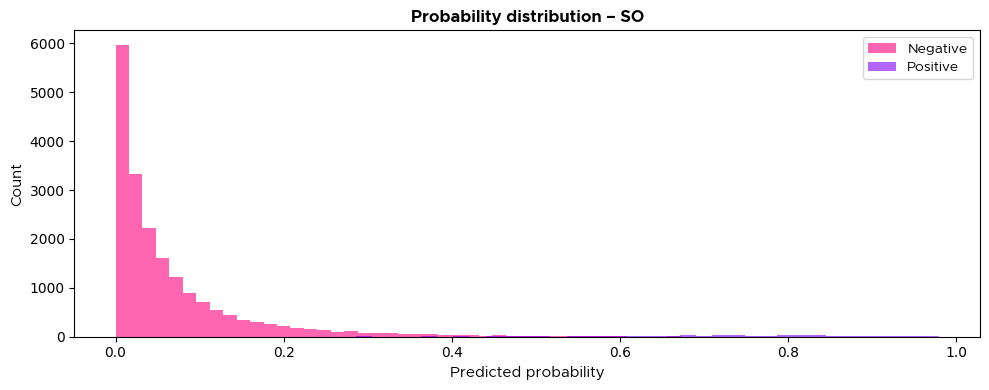


=== EM ===
Positives: 2176 | Negatives: 17749
Mean prob (pos): 0.4849
Mean prob (neg): 0.1717
AUC: 0.9322


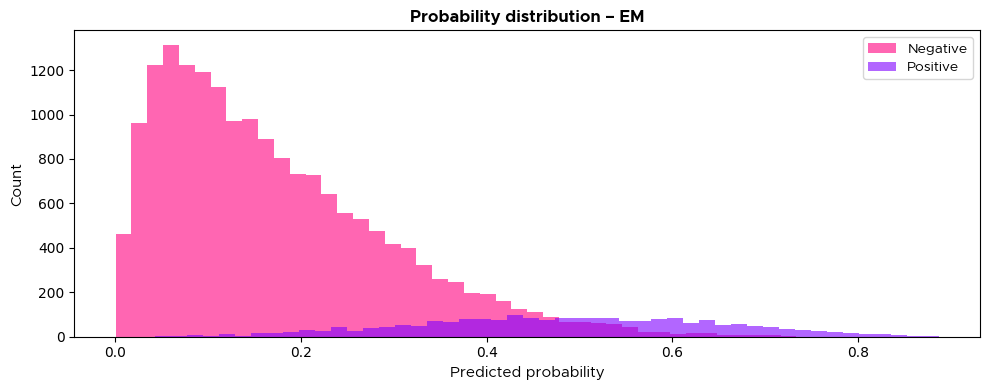


=== BI ===
Positives: 1066 | Negatives: 18859
Mean prob (pos): 0.5443
Mean prob (neg): 0.1062
AUC: 0.9610


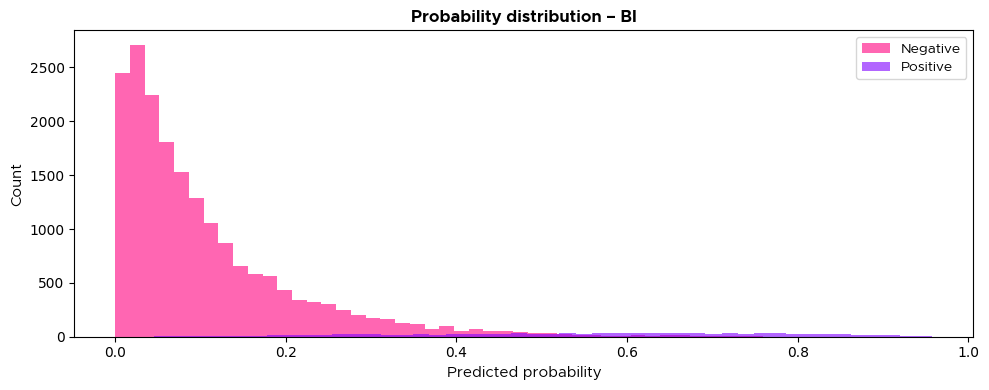


=== GE ===
Positives: 1921 | Negatives: 18004
Mean prob (pos): 0.4575
Mean prob (neg): 0.1722
AUC: 0.8770


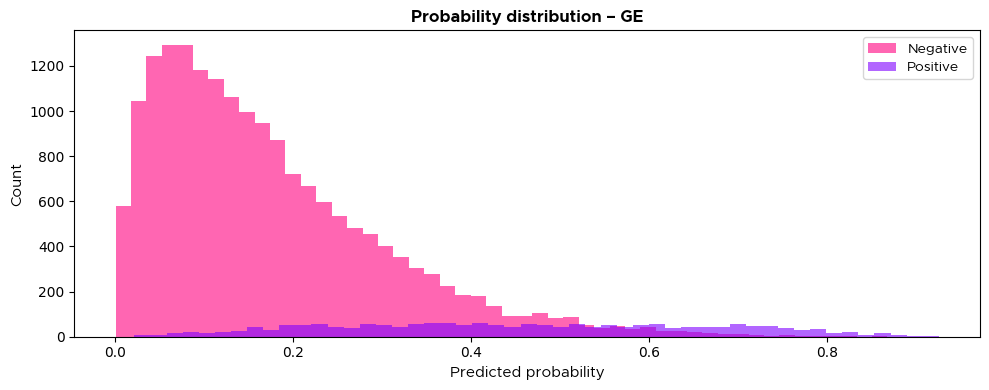


=== TM ===
Positives: 6834 | Negatives: 13091
Mean prob (pos): 0.4891
Mean prob (neg): 0.1933
AUC: 0.9176


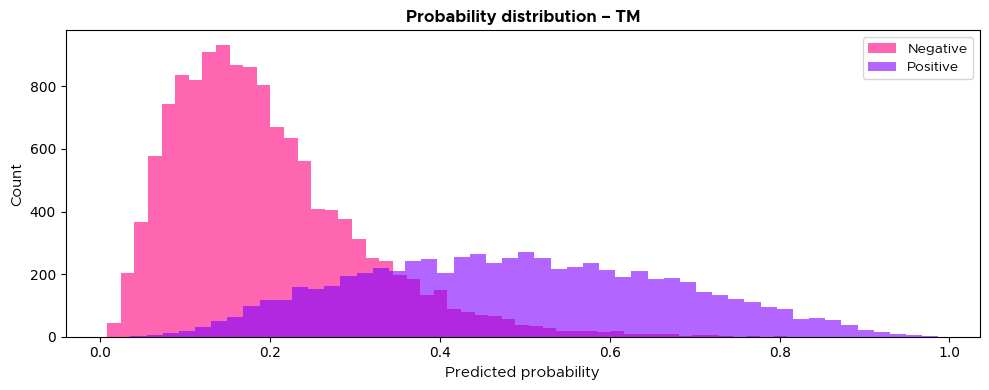


=== MH ===
Positives: 3763 | Negatives: 16162
Mean prob (pos): 0.4947
Mean prob (neg): 0.2046
AUC: 0.8747


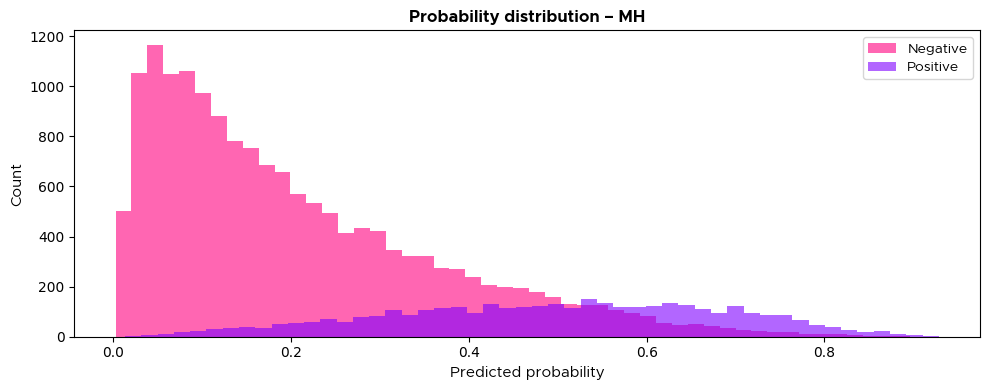


=== VO ===
Positives: 7367 | Negatives: 12558
Mean prob (pos): 0.4872
Mean prob (neg): 0.2303
AUC: 0.8776


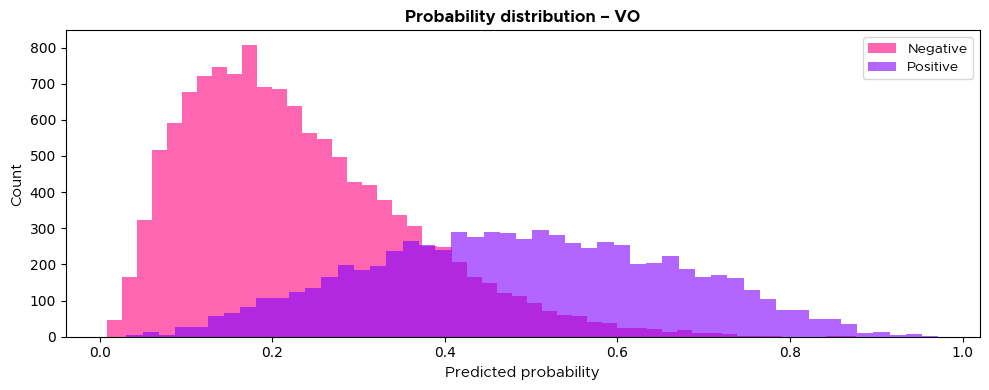


=== MU ===
Positives: 2061 | Negatives: 17864
Mean prob (pos): 0.5597
Mean prob (neg): 0.1286
AUC: 0.9529


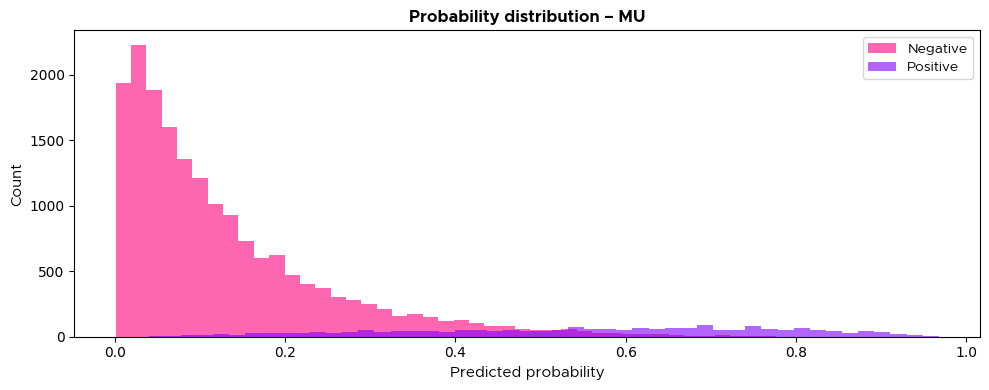


=== SI ===
Positives: 2215 | Negatives: 17710
Mean prob (pos): 0.6458
Mean prob (neg): 0.1107
AUC: 0.9631


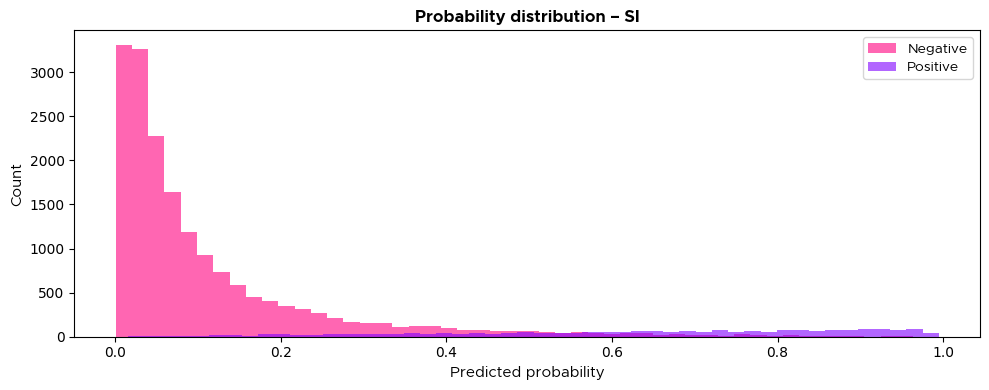

In [22]:
# LOOK AT PROBABILITIES DISTRIBUTIONS PER CLASS

diagnose_label(test_probs, "SO")
diagnose_label(test_probs, "EM")
diagnose_label(test_probs, "BI")
diagnose_label(test_probs, "GE")
diagnose_label(test_probs, "TM")
diagnose_label(test_probs, "MH")
diagnose_label(test_probs, "VO")
diagnose_label(test_probs, "MU")
diagnose_label(test_probs, "SI")